# GENIE BPC CRC v2.0-public — questions C1–C4

Source: Jacob's *CBIO thoughts* deck, slides 19–23. Data: AACR Project GENIE BPC CRC v2.0-public (Synapse).

Conventions as in `README.md`: index date = diagnosis of the index colorectal cancer, OS in months; *X mut* = non-synonymous mutation;
`amp` / `homdel` / `fus` separate; patients compared for a gene only if their panel covers it; KM / log-rank as cBioPortal, Cox HR left-truncated at the sequencing report (*HR (LT)*).

**Sample timing.** The cancer-panel-test table gives, for every sequenced sample, the months from diagnosis to the pathology procedure that
produced it (`dx_path_proc_cpt_mos`). A sample is *pre-treatment* for a regimen class if it was collected before the first regimen of that class
started, *post-treatment* otherwise. Leucovorin marks the FOLFOX / FOLFIRI / CAPOX-type backbones.

In [1]:
import sys, re, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cbio_lib.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cbio_lib as cb

cb.setup_plots()
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3g}".format
pd.options.display.width = 200
DS = "bpc_crc"
F = []

b = cb.BPC("CRC")
pd.Series(b.summary())

cohort                              CRC
patients                           1485
index_cancers                      1494
patients_with_2+_index_cancers        8
samples                            1550
samples_used                       1485
regimens                           5100
mutations_nonsyn                  22257
cna_profiled_samples               1487
sv_rows                             403
dtype: object

## Data pin

In [2]:
log = pd.read_csv(cb.DATA / "genie" / "download_log.csv")
print("release_version:", b.index.release_version.unique())
log[log.cohort == "CRC"][[c for c in ["category", "filename", "synapse_id", "version", "md5"] if c in log.columns]]

release_version: ['2.0-public']


,category,filename,synapse_id,version,md5
0,docs,GENIE BPC CRC v2.0-public Analytic Data Guide ...,syn39433168,3,82cfbc337ffbdfe5ee8ae909952b4485
1,docs,BPC_CRC_v2.0-public_variable_synopsis.xlsx,syn39433163,2,d4060d4b17b9917f148f0a33ab279455
2,analytic,patient_level_dataset.csv,syn39802589,2,dbc75fd101a00e8220b7d4c681dd4779
3,analytic,cancer_level_dataset_index.csv,syn39802574,2,ad97b314604282c6adecb9a42d8bcc45
4,analytic,cancer_level_dataset_non_index.csv,syn39802575,2,1903e5f6ceebbe52914d6565c22c1420
5,analytic,cancer_panel_test_level_dataset.csv,syn39802578,2,431d8b6ec316c0b22bfb19b57856d2e7
6,analytic,regimen_cancer_level_dataset.csv,syn39802591,2,722dd78feab23506336dff70ef9c2294
7,analytic,imaging_level_dataset.csv,syn39802579,2,7c5a6ccac2c43a0a55ee2eda9fce7697
8,analytic,med_onc_note_level_dataset.csv,syn39802583,2,663451e24d6139ba7663b5321200573f
9,analytic,pathology_report_level_dataset.csv,syn39802586,2,f5cd4e7c30b1229d3feb564ebe8d5453


## Cohort, alteration matrix and sample timing

,step,n,dropped
0,Patients in release,1485,0
1,Index CRC (first index cancer per patient),1485,0
2,With a sequenced sample of the index cancer,1485,0
3,With OS from diagnosis,1485,0


8 patients had two index cancers (first used); 0 samples with unknown panel; 96 patients with sequencing report after last follow-up (dropped from left-truncated models only).
Deaths: 690 / 1485.  Median OS from dx: 63.2 months.


stage_dx
Stage IV           701
Stage III          461
Stage II           222
Stage I             94
Stage I-III NOS      6
Name: stage_dx, dtype: int64

PosixPath('/Users/daniel/Code/explore-genie/results/bpc_crc/cohort_gene_frequency')

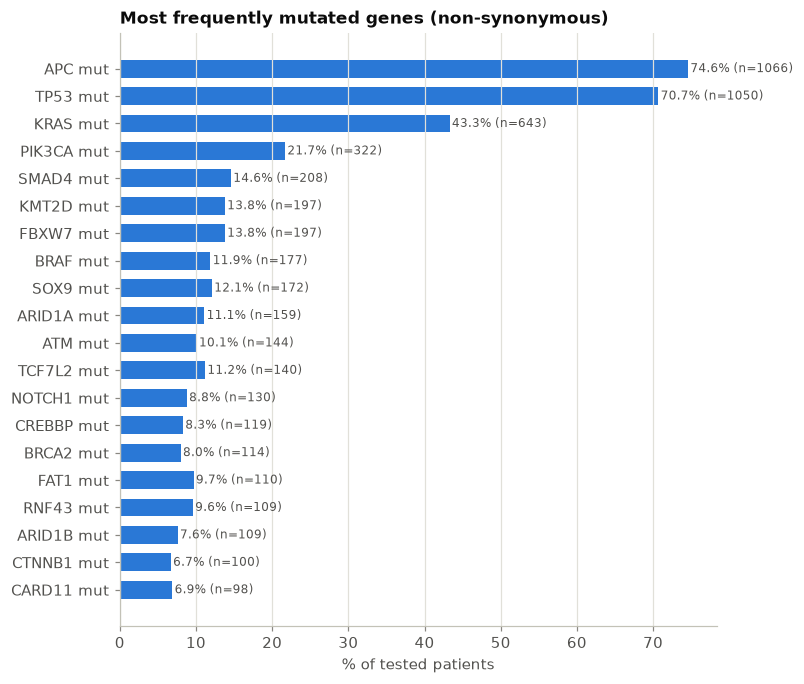

In [3]:
S = b.survival_dx()
A = b.alterations()
display(cb.consort([
    ("Patients in release", len(b.patients)),
    ("Index CRC (first index cancer per patient)", len(b.index)),
    ("With a sequenced sample of the index cancer", int(S.entry.notna().sum())),
    ("With OS from diagnosis", int(S.time.notna().sum())),
]))
print(f"{b.n_multi_index} patients had two index cancers (first used); {A.n_unknown_panel} samples with unknown panel; "
      f"{int((S.entry >= S.time).sum())} patients with sequencing report after last follow-up (dropped from left-truncated models only).")
print(f"Deaths: {int(S.event.sum())} / {len(S)}.  Median OS from dx: {cb.km_table(S.assign(g='all'), 'g').median_months[0]} months.")
display(S.stage_dx.value_counts().rename("stage_dx"))
freq = A.frequency(kinds=("mut", "amp", "homdel", "fus"))
ax = cb.bar_freq(freq[freq.kind == "mut"], top=20, title="Most frequently mutated genes (non-synonymous)")
cb.save(DS, "cohort", table=freq, fig=ax.figure, slug="gene_frequency")

In [4]:
# first regimen start per class, per patient (months from diagnosis)
rg = b.regimens
def first_start(mask):
    return rg[mask].groupby("record_id").dx_reg_start_int_mos.min()
leu_start = first_start(rg.regimen_drugs.fillna("").str.contains("Leucovorin", case=False))
chemo_start = first_start(cb.contains_any(rg.regimen_drugs, cb.CHEMO))
samp = b.samples_all.copy()                                   # every sequenced sample of the index cancer
samp["collected_mos"] = samp.dx_path_proc_cpt_mos
samp["leu_start"] = samp.patient_id.map(leu_start)
samp["chemo_start"] = samp.patient_id.map(chemo_start)
samp["timing_leu"] = np.select([samp.leu_start.isna(), samp.collected_mos < samp.leu_start], ["no leucovorin regimen", "pre-leucovorin"], default="post-leucovorin")
samp["timing_chemo"] = np.select([samp.chemo_start.isna(), samp.collected_mos < samp.chemo_start], ["no chemotherapy", "pre-chemotherapy"], default="post-chemotherapy")
display(pd.crosstab(samp.timing_leu, samp.sample_type, margins=True))
print("regimens containing leucovorin:", rg.regimen_drugs.fillna("").str.contains("Leucovorin", case=False).sum(), "| top:")
display(rg[rg.regimen_drugs.fillna("").str.contains("Leucovorin", case=False)].regimen_drugs.value_counts().head(8))

sample_type,Local recurrence,Lymph node metastasis,Metastasis site unspecified,Not applicable or hematologic malignancy,Primary tumor,All
timing_leu,,,,,,
no leucovorin regimen,0,0,33,0,215,248
post-leucovorin,6,2,325,1,103,437
pre-leucovorin,6,1,166,6,686,865
All,12,3,524,7,1004,1550


regimens containing leucovorin: 3063 | top:


regimen_drugs
Fluorouracil, Leucovorin Calcium, Oxaliplatin                              1013
Bevacizumab, Fluorouracil, Irinotecan Hydrochloride, Leucovorin Calcium     616
Bevacizumab, Fluorouracil, Leucovorin Calcium, Oxaliplatin                  463
Fluorouracil, Irinotecan Hydrochloride, Leucovorin Calcium                  407
Fluorouracil, Leucovorin Calcium                                            126
Bevacizumab, Fluorouracil, Leucovorin Calcium                                88
Cetuximab, Fluorouracil, Irinotecan Hydrochloride, Leucovorin Calcium        78
Fluorouracil, Irinotecan Hydrochloride, Leucovorin Calcium, Panitumumab      55
Name: count, dtype: int64

## C1 (replicate) — OS of patients biopsied before leucovorin vs after leucovorin was very different
Slides 19–21. Patient-level: the earliest sample of the index cancer, classified pre / post the first leucovorin-containing regimen.
A post-treatment biopsy can only happen in a patient who survived treatment, so OS from diagnosis is inflated for the post group
(immortal time). Corrections: OS from sample collection, and a Cox model left-truncated at sample collection, stage- and age-adjusted.

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,pre-leucovorin,855,435,52.3,0.929,0.769,0.443,2.38e-10
1,post-leucovorin,382,198,72.6,0.984,0.898,0.609,2.38e-10
2,no leucovorin regimen,248,57,112,0.912,0.829,0.718,2.38e-10


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,pre-leucovorin,855,435,47.6,0.923,0.746,0.421,0.642
1,post-leucovorin,382,198,44.7,0.871,0.739,0.405,0.642


,model,HR,HR_lo,HR_hi,p_cox,n_cox
0,"naive, OS from dx",0.608,0.511,0.722,1.38e-08,1237
1,left-truncated at sample collection,0.895,0.749,1.07,0.225,1237
2,left-truncated + stage + age,0.806,0.671,0.968,0.0207,1237
3,"stage IV only, left-truncated + age",0.701,0.556,0.884,0.00267,656


[C1] replicated, but it is immortal-time bias: From dx: pre n=855 median 52.3 vs post n=382 median 72.6 mo, p=2.4e-10, naive HR post vs pre 0.61. From sample collection: median 47.6 vs 44.7 mo, p=0.642; left-truncated + stage + age HR 0.81 (p=0.021).


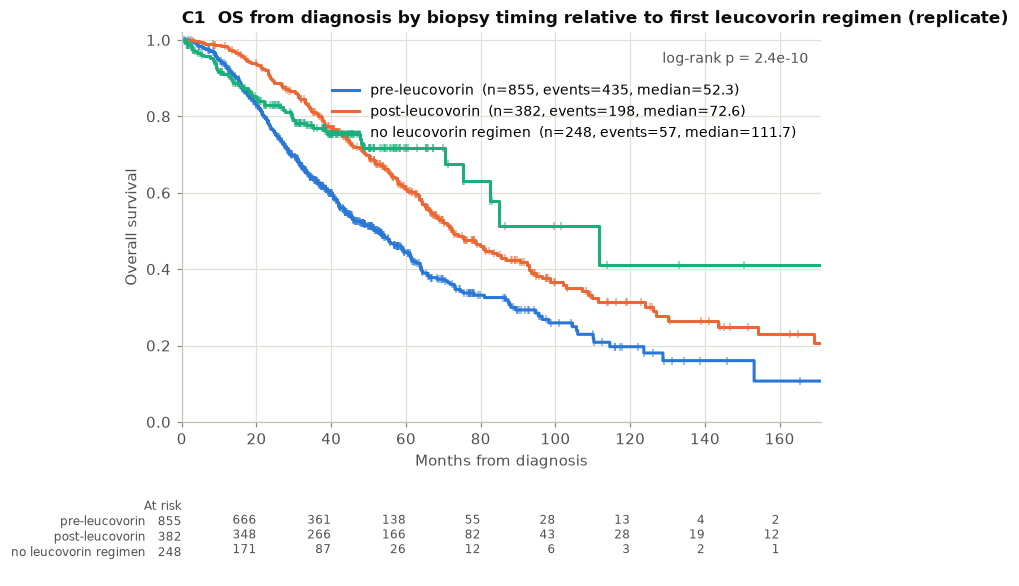

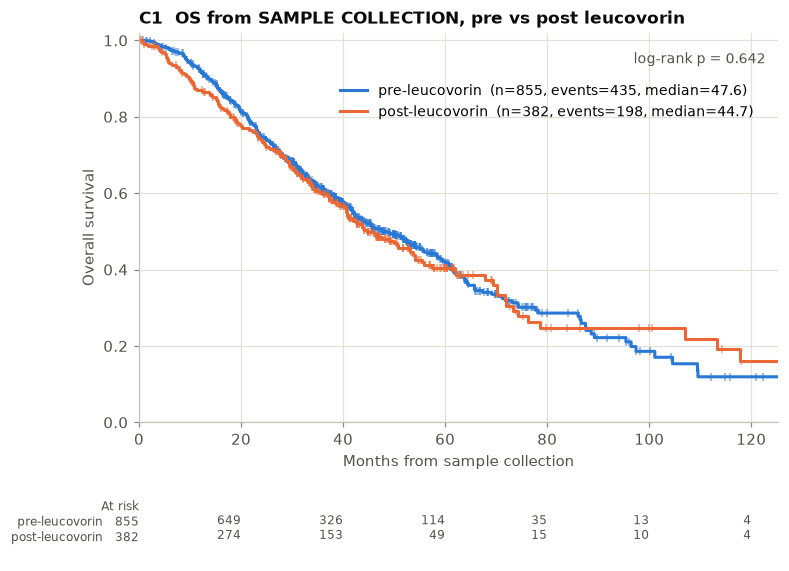

In [5]:
first = samp.sort_values(["patient_id", "collected_mos"]).drop_duplicates("patient_id").set_index("patient_id")
S["timing_leu"] = first.timing_leu.reindex(S.index)
S["collected_mos"] = first.collected_mos.reindex(S.index)
S["time_from_sample"] = (S.time - S.collected_mos)
S["entry_sample"] = S.collected_mos.clip(lower=0)
order1 = ["pre-leucovorin", "post-leucovorin", "no leucovorin regimen"]
ax, t1 = cb.km_plot(S, "timing_leu", order=order1, title="C1  OS from diagnosis by biopsy timing relative to first leucovorin regimen (replicate)", xlabel="Months from diagnosis")
cb.save(DS, "C1", table=t1, fig=ax.figure, slug="os_from_dx_replicate")
display(t1)
two = S[S.timing_leu.isin(order1[:2])].copy()
two["post"] = two.timing_leu.eq("post-leucovorin")
ax, t1b = cb.km_plot(two, "timing_leu", time="time_from_sample", order=order1[:2], title="C1  OS from SAMPLE COLLECTION, pre vs post leucovorin", xlabel="Months from sample collection")
cb.save(DS, "C1", table=t1b, fig=ax.figure, slug="os_from_sample")
display(t1b)
models = pd.DataFrame([
    dict(model="naive, OS from dx", **cb.hr(two, "post")),
    dict(model="left-truncated at sample collection", **cb.hr(two, "post", entry="entry_sample")),
    dict(model="left-truncated + stage + age", **cb.hr(two, "post", entry="entry_sample", adjust=["stage_dx", "age_dx"])),
    dict(model="stage IV only, left-truncated + age", **cb.hr(two[two.stage_dx == "Stage IV"], "post", entry="entry_sample", adjust=["age_dx"])),
])
cb.save(DS, "C1", table=models, slug="cox_models")
display(models)
cb.finding("C1", "replicated, but it is immortal-time bias",
           f"From dx: pre n={t1.n[0]} median {t1.median_months[0]} vs post n={t1.n[1]} median {t1.median_months[1]} mo, p={cb.fmt_p(t1.p_logrank[0])}, naive HR post vs pre {models.HR[0]:.2f}. "
           f"From sample collection: median {t1b.median_months[0]} vs {t1b.median_months[1]} mo, p={cb.fmt_p(t1b.p_logrank[0])}; left-truncated + stage + age HR {models.HR[2]:.2f} (p={cb.fmt_p(models.p_cox[2])}).", F)

## C2 — How do mutational profiles differ in samples taken before vs after chemotherapy?
Sample-level comparison (every sequenced sample, classified against the first chemotherapy regimen of any kind and, separately, the first leucovorin regimen). Fisher test per gene feature, BH FDR. Samples from the same patient are not independent; C3 handles the paired subset.

timing_chemo: 503 post vs 874 pre samples


,gene,kind,n_post,altered_post,pct_post,n_pre,altered_pre,pct_pre,p_fisher,q_bh
164,BCL2,homdel,475,10,2.1,847,3,0.4,0.00302,1
106,CSF3R,mut,403,13,3.2,737,6,0.8,0.00588,1
3,PIK3CA,mut,503,80,15.9,874,192,22,0.00748,1
289,EPCAM,mut,348,5,1.4,552,0,0,0.00849,1
112,ZNF217,amp,187,13,7,473,11,2.3,0.00908,1
64,NKX3-1,homdel,407,18,4.4,740,14,1.9,0.0152,1
200,FGFR1,homdel,475,8,1.7,847,3,0.4,0.0215,1
194,MALT1,homdel,356,8,2.2,481,2,0.4,0.0219,1
185,PMAIP1,homdel,288,8,2.8,374,2,0.5,0.0242,1
302,CARD11,amp,475,5,1.1,847,1,0.1,0.0249,1


timing_leu: 437 post vs 865 pre samples


,gene,kind,n_post,altered_post,pct_post,n_pre,altered_pre,pct_pre,p_fisher,q_bh
94,CSF3R,mut,349,13,3.7,723,3,0.4,7.8e-05,0.0433
155,BCL2,homdel,412,9,2.2,837,3,0.4,0.00341,0.846
246,RAC1,amp,412,6,1.5,837,1,0.1,0.00634,0.846
271,EPCAM,mut,310,5,1.6,535,0,0,0.00651,0.846
126,ZNF217,amp,146,11,7.5,478,11,2.3,0.00761,0.846
0,TP53,mut,437,335,76.7,865,608,70.3,0.0152,1
277,CARD11,amp,412,5,1.2,837,1,0.1,0.0168,1
68,NKX3-1,homdel,352,16,4.5,727,14,1.9,0.0177,1
267,CASP8,mut,371,5,1.3,645,26,4,0.0214,1
120,SMARCB1,mut,413,11,2.7,837,8,1,0.0265,1


[C2] no difference at FDR<0.1: Pre vs post chemotherapy, FDR<0.1: none. Nominal top: BCL2 homdel 0.4% -> 2.1% (p=0.003).


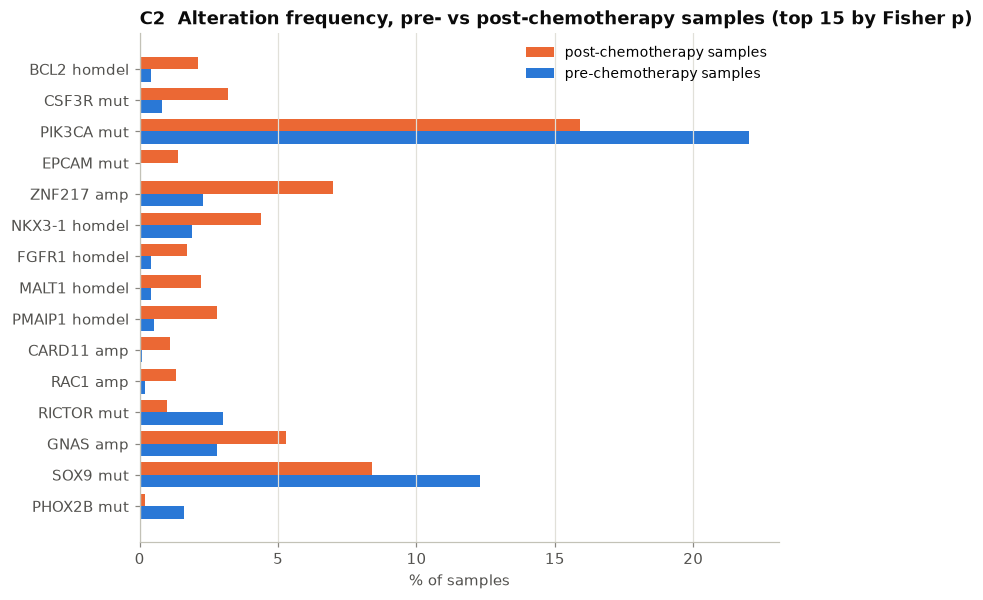

In [6]:
As = b.alterations(rule="any")   # not used directly; build a sample-level matrix below
sample_level = samp[["sample_id"]].assign(patient_id=samp.sample_id)         # treat each sample as its own unit
AS = cb.build_alterations(sample_level, b.mut_long, b.cna_long, b.sv_long, b.panel_of, b.panel_genes)
res2 = {}
for col, post_label, pre_label in [("timing_chemo", "post-chemotherapy", "pre-chemotherapy"), ("timing_leu", "post-leucovorin", "pre-leucovorin")]:
    sub = samp[samp[col].isin([pre_label, post_label])].set_index("sample_id")
    anchor = sub[col].eq(post_label)
    co = AS.cooccurrence(anchor, kinds=("mut", "amp", "homdel"), min_n=5)
    co = co.rename(columns={"n_anchor": "n_post", "altered_in_anchor": "altered_post", "pct_in_anchor": "pct_post",
                            "n_rest": "n_pre", "altered_in_rest": "altered_pre", "pct_in_rest": "pct_pre"}).sort_values("p_fisher")
    res2[col] = co
    cb.save(DS, "C2", table=co, slug=f"{col}_frequencies")
    print(f"{col}: {int(anchor.sum())} post vs {int((~anchor).sum())} pre samples")
    display(co.head(12))
top = res2["timing_chemo"].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 6))
y = np.arange(len(top))
ax.barh(y + 0.2, top.pct_post, height=0.4, color=cb.PALETTE[1], label="post-chemotherapy samples")
ax.barh(y - 0.2, top.pct_pre, height=0.4, color=cb.PALETTE[0], label="pre-chemotherapy samples")
ax.set_yticks(y); ax.set_yticklabels(top.gene + " " + top.kind); ax.set_xlabel("% of samples"); ax.legend()
ax.set_title("C2  Alteration frequency, pre- vs post-chemotherapy samples (top 15 by Fisher p)", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
cb.save(DS, "C2", fig=fig, slug="pre_vs_post_chemo")
sig2 = res2["timing_chemo"][res2["timing_chemo"].q_bh < 0.1]
cb.finding("C2", "signal" if len(sig2) else "no difference at FDR<0.1",
           "Pre vs post chemotherapy, FDR<0.1: " + (", ".join(f"{r.gene} {r.kind} {r.pct_pre}% -> {r.pct_post}%" for r in sig2.itertuples()) or "none") +
           f". Nominal top: {res2['timing_chemo'].gene.iloc[0]} {res2['timing_chemo'].kind.iloc[0]} {res2['timing_chemo'].pct_pre.iloc[0]}% -> {res2['timing_chemo'].pct_post.iloc[0]}% (p={cb.fmt_p(res2['timing_chemo'].p_fisher.iloc[0])}).", F)

## C3 — How many patients have both pre- and post-chemotherapy biopsies, and how did their mutations change?
Within-patient comparison: one pre- and one post-chemotherapy sample (earliest of each), restricted to genes on both samples' panels.

patients with >=1 pre and >=1 post-chemotherapy sample: 26 (of 1485 sequenced patients)


,kept,gained,lost
kind,,,
amp,18,31,44
homdel,1,12,7
mut,98,50,37


,gene,kind,change,n_patients
151,TP53,mut,gained,4
70,GNAS,amp,lost,3
10,AURKA,amp,gained,3
0,ALK,mut,gained,2
114,PIK3R1,mut,gained,2
37,CDKN2B,homdel,gained,2
35,CDKN2A,homdel,gained,2
129,RARA,amp,gained,2
131,RET,mut,lost,2
30,CDK12,amp,gained,2


[C3] descriptive: 26 patients have paired pre/post-chemotherapy samples. Mutations gained 50, lost 37, kept 98. Most often gained: TP53 mut (n=4), AURKA amp (n=3), ALK mut (n=2), PIK3R1 mut (n=2), CDKN2B homdel (n=2).


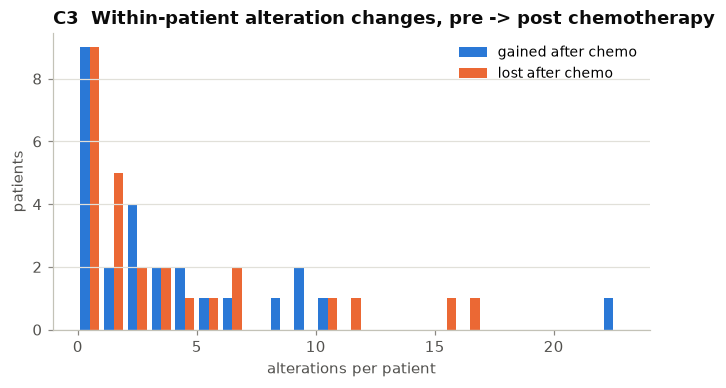

In [7]:
pre = samp[samp.timing_chemo == "pre-chemotherapy"].sort_values("collected_mos").drop_duplicates("patient_id").set_index("patient_id")
post = samp[samp.timing_chemo == "post-chemotherapy"].sort_values("collected_mos").drop_duplicates("patient_id").set_index("patient_id")
paired = pre.index.intersection(post.index)
print(f"patients with >=1 pre and >=1 post-chemotherapy sample: {len(paired)} (of {samp.patient_id.nunique()} sequenced patients)")
rows, per_patient = [], []
for pid in paired:
    s1, s2 = pre.loc[pid, "sample_id"], post.loc[pid, "sample_id"]
    for kind in ["mut", "amp", "homdel"]:
        M, T = AS.matrix(kind), AS.tested_for(kind)
        both_tested = T.loc[s1] & T.loc[s2]
        a1, a2 = M.loc[s1] & both_tested, M.loc[s2] & both_tested
        gained, lost, kept = a2 & ~a1, a1 & ~a2, a1 & a2
        per_patient.append(dict(patient_id=pid, kind=kind, months_between=round(post.loc[pid, "collected_mos"] - pre.loc[pid, "collected_mos"], 1),
                                n_tested=int(both_tested.sum()), kept=int(kept.sum()), gained=int(gained.sum()), lost=int(lost.sum()),
                                gained_genes=",".join(gained.index[gained]), lost_genes=",".join(lost.index[lost])))
        for g in gained.index[gained]: rows.append(dict(gene=g, kind=kind, change="gained"))
        for g in lost.index[lost]: rows.append(dict(gene=g, kind=kind, change="lost"))
pp = pd.DataFrame(per_patient)
ch = pd.DataFrame(rows)
ch = ch.groupby(["gene", "kind", "change"]).size().rename("n_patients").reset_index().sort_values("n_patients", ascending=False) if len(ch) else ch
cb.save(DS, "C3", table=pp, slug="per_patient_changes")
cb.save(DS, "C3", table=ch, slug="gene_changes")
display(pp.groupby("kind")[["kept", "gained", "lost"]].sum())
display(ch.head(20))
if len(pp):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    tot = pp.groupby("patient_id")[["gained", "lost"]].sum()
    ax.hist([tot.gained, tot.lost], bins=range(0, int(max(tot.max().max(), 1)) + 2), label=["gained after chemo", "lost after chemo"], color=cb.PALETTE[:2])
    ax.set_xlabel("alterations per patient"); ax.set_ylabel("patients"); ax.legend()
    ax.set_title("C3  Within-patient alteration changes, pre -> post chemotherapy", loc="left", fontweight="bold")
    cb.save(DS, "C3", fig=fig, slug="changes_hist")
cb.finding("C3", "descriptive",
           f"{len(paired)} patients have paired pre/post-chemotherapy samples. " +
           (f"Mutations gained {int(pp[pp.kind == 'mut'].gained.sum())}, lost {int(pp[pp.kind == 'mut'].lost.sum())}, kept {int(pp[pp.kind == 'mut'].kept.sum())}. Most often gained: " +
            ", ".join(f"{r.gene} {r.kind} (n={r.n_patients})" for r in ch[ch.change == 'gained'].head(5).itertuples()) if len(pp) else "") + ".", F)

## C4 — How does mutation status affect survival: KRAS vs TP53 vs APC, plus co-mutations
Single-gene comparisons (overlapping), then mutually exclusive profiles over the three genes (restricted to patients tested for all three), OS from diagnosis, HR (LT) adjusted for stage and age.

n  events  median_months  surv_1y  surv_2y  surv_5y  p_logrank    HR  HR_lo  HR_hi    p_cox  HR_adj_stage_age
gene   group                                                                                                                       
KRAS   KRAS wt      842     360           68.2    0.944     0.84    0.559   3.89e-05   NaN    NaN    NaN      NaN               NaN
       KRAS mut     643     330           54.5    0.936    0.775    0.468   3.89e-05  1.41   1.21   1.65 9.23e-06              1.44
TP53   TP53 wt      435     198           67.2    0.939    0.823    0.558      0.311   NaN    NaN    NaN      NaN               NaN
       TP53 mut    1050     492             61    0.941    0.807    0.502      0.311   1.1  0.927    1.3    0.276              0.98
APC    APC wt       362     184           51.5    0.909     0.74    0.426   5.93e-05   NaN    NaN    NaN      NaN               NaN
       APC mut     1066     470           67.2    0.955    0.844    0.557   5.93e-05 0.778  0.652  0.927  0.00513              0.76
NRAS   NRAS wt     1407     652           63.6     0.94    0.811    0.521      0.408   NaN    NaN    NaN      NaN               NaN
       NRAS mut      78      38           55.1    0.948    0.824    0.486      0.408 0.995  0.704   1.41    0.976              1.13
BRAF   BRAF wt     1308     611           63.8     0.95    0.828    0.527     0.0712   NaN    NaN    NaN      NaN               NaN
       BRAF mut     177      79           55.9     0.87    0.686    0.462     0.0712 0.946  0.734   1.22    0.668              1.03
PIK3CA PIK3CA wt   1163     561           61.4     0.94    0.807    0.507     0.0406   NaN    NaN    NaN      NaN               NaN
       PIK3CA mut   322     129           72.9    0.943    0.828    0.568     0.0406 0.733  0.603  0.891  0.00184             0.794
SMAD4  SMAD4 wt    1220     549           64.3    0.945    0.823    0.537     0.0382   NaN    NaN    NaN      NaN               NaN
       SMAD4 mut    208     105             54    0.931    0.791    0.457     0.0382  1.17  0.944   1.46     0.15              1.22
FBXW7  FBXW7 wt    1231     579           63.2    0.942    0.819    0.521      0.385   NaN    NaN    NaN      NaN               NaN
       FBXW7 mut    197      75             65    0.953    0.809    0.558      0.385 0.748  0.583  0.959   0.0223             0.861

profile
TP53+APC             474
KRAS+TP53+APC        289
KRAS+APC             197
TP53                 159
APC                  106
KRAS+TP53             92
none of the three     71
KRAS                  40
Name: patients, dtype: int64

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,none of the three,71,36,51.5,0.926,0.792,0.445,7.97e-08
1,KRAS,40,18,59.8,0.9,0.795,0.463,7.97e-08
2,TP53,159,81,55.6,0.929,0.734,0.448,7.97e-08
3,APC,106,37,95.4,0.961,0.888,0.695,7.97e-08
4,KRAS+TP53,92,49,44,0.866,0.688,0.334,7.97e-08
5,KRAS+APC,197,93,64.7,0.948,0.831,0.562,7.97e-08
6,TP53+APC,474,189,72.8,0.955,0.883,0.591,7.97e-08
7,KRAS+TP53+APC,289,151,51.8,0.957,0.774,0.448,7.97e-08


,HR,HR_lo,HR_hi,p
covariate,,,,
profile_KRAS,0.734,0.41,1.31,0.297
profile_TP53,0.865,0.577,1.3,0.481
profile_APC,0.616,0.382,0.992,0.0465
profile_KRAS+TP53,1.3,0.836,2.03,0.242
profile_KRAS+APC,0.82,0.554,1.21,0.321
profile_TP53+APC,0.586,0.407,0.845,0.00417
profile_KRAS+TP53+APC,1.01,0.696,1.46,0.964


[C4] signal: Single genes (HR adj. stage/age): KRAS 1.44, TP53 0.98, APC 0.76, BRAF 1.03. Profiles vs none, adjusted: KRAS+TP53 HR 1.30 (p=0.242), KRAS+TP53+APC HR 1.01 (p=0.964), TP53 HR 0.86 (p=0.481). Log-rank across profiles p=8.0e-08.


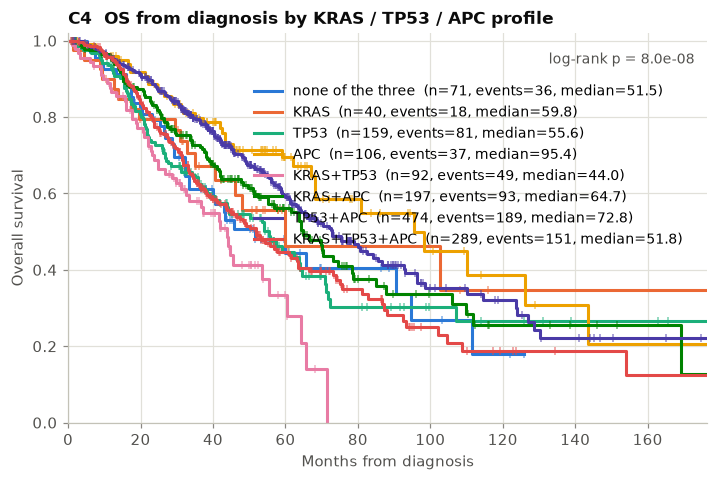

In [8]:
rows = []
for g in ["KRAS", "TP53", "APC", "NRAS", "BRAF", "PIK3CA", "SMAD4", "FBXW7"]:
    d, t = cb.compare(S, A.status(g), labels=(f"{g} wt", f"{g} mut"), entry="entry")
    hadj = cb.hr(d, "feat", entry="entry", adjust=["stage_dx", "age_dx"])
    t["HR_adj_stage_age"] = np.nan; t.loc[1, "HR_adj_stage_age"] = hadj["HR"]
    rows.append(t.assign(gene=g))
single = pd.concat(rows).set_index(["gene", "group"])
cb.save(DS, "C4", table=single.reset_index(), slug="single_genes")
display(single)
prof = A.combo_groups(["KRAS", "TP53", "APC"], min_n=10, wt_label="none of the three")
order4 = [g for g in ["none of the three", "KRAS", "TP53", "APC", "KRAS+TP53", "KRAS+APC", "TP53+APC", "KRAS+TP53+APC", "other combination"] if g in set(prof)]
d4 = S.join(prof, how="inner")
display(d4.profile.value_counts().rename("patients"))
ax, t4 = cb.km_plot(d4, "profile", order=order4, title="C4  OS from diagnosis by KRAS / TP53 / APC profile", xlabel="Months from diagnosis", risk_table=False)
d4c = d4.assign(profile=pd.Categorical(d4.profile, order4))
_, cox4 = cb.cox_fit(d4c, ["profile", "stage_dx", "age_dx"], entry="entry")
cb.save(DS, "C4", table=t4, fig=ax.figure, slug="profiles_os")
cb.save(DS, "C4", table=cox4, slug="profiles_cox_adjusted")
display(t4)
display(cox4.loc[cox4.index.str.startswith("profile")])
worst = cox4.loc[cox4.index.str.startswith("profile")].sort_values("HR", ascending=False).head(3)
cb.finding("C4", "signal" if (cox4.loc[cox4.index.str.startswith('profile')].p < 0.05).any() else "no signal",
           "Single genes (HR adj. stage/age): " + ", ".join(f"{g} {single.loc[(g, f'{g} mut'), 'HR_adj_stage_age']:.2f}" for g in ["KRAS", "TP53", "APC", "BRAF"]) +
           ". Profiles vs none, adjusted: " + ", ".join(f"{i.replace('profile_', '')} HR {r.HR:.2f} (p={cb.fmt_p(r.p)})" for i, r in worst.iterrows()) +
           f". Log-rank across profiles p={cb.fmt_p(t4.p_logrank[0])}.", F)

## Summary of findings

In [9]:
fd = pd.DataFrame(F)
cb.save(DS, "findings", table=fd)
pd.set_option("display.max_colwidth", 400)
fd

,question,verdict,note
0,C1,"replicated, but it is immortal-time bias","From dx: pre n=855 median 52.3 vs post n=382 median 72.6 mo, p=2.4e-10, naive HR post vs pre 0.61. From sample collection: median 47.6 vs 44.7 mo, p=0.642; left-truncated + stage + age HR 0.81 (p=0.021)."
1,C2,no difference at FDR<0.1,"Pre vs post chemotherapy, FDR<0.1: none. Nominal top: BCL2 homdel 0.4% -> 2.1% (p=0.003)."
2,C3,descriptive,"26 patients have paired pre/post-chemotherapy samples. Mutations gained 50, lost 37, kept 98. Most often gained: TP53 mut (n=4), AURKA amp (n=3), ALK mut (n=2), PIK3R1 mut (n=2), CDKN2B homdel (n=2)."
3,C4,signal,"Single genes (HR adj. stage/age): KRAS 1.44, TP53 0.98, APC 0.76, BRAF 1.03. Profiles vs none, adjusted: KRAS+TP53 HR 1.30 (p=0.242), KRAS+TP53+APC HR 1.01 (p=0.964), TP53 HR 0.86 (p=0.481). Log-rank across profiles p=8.0e-08."
